## ChatBot - Memory + Streaming

In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [2]:
from langchain_groq import ChatGroq

llm=ChatGroq(model="openai/gpt-oss-120b")

In [3]:
class State(TypedDict):
    messages:Annotated[list,add_messages]

## Memory

In [4]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [5]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

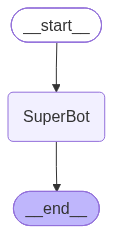

In [6]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [7]:
## Invocation

config = {"configurable": {"thread_id": "1"}}
graph_builder.invoke({'messages':"Hi,My name is Garvit And I like cricket"},config)

{'messages': [HumanMessage(content='Hi,My name is Garvit And I like cricket', additional_kwargs={}, response_metadata={}, id='0f3841f3-5d97-4028-b214-a7730a32927c'),
  AIMessage(content="Hello Garvit! 👋 Great to meet you.  \n\nCricket is such an exciting sport—whether it’s the drama of a Test match, the fireworks of a T20, or the strategy of an ODI. Do you have a favorite team or player you follow? And do you enjoy playing cricket yourself, or are you more of a fan watching the games? I'd love to hear more!", additional_kwargs={'reasoning_content': 'The user says "Hi, My name is Garvit And I like cricket". Probably a greeting and sharing interests. The assistant should respond friendly, maybe ask about cricket preferences, maybe ask about favorite team, etc. No disallowed content. Just respond.'}, response_metadata={'token_usage': {'completion_tokens': 141, 'prompt_tokens': 82, 'total_tokens': 223, 'completion_time': 0.296056781, 'completion_tokens_details': {'reasoning_tokens': 52}, '

## Streaming

Methods: .stream() and astream()

These methods are sync and async methods for streaming back results.
Additional parameters in streaming modes for graph state

a. values : This streams the full state of the graph after each node is called.

b. updates : This streams updates to the state of the graph after each node is called.

In [8]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hello Krish! 👋 Great to meet you.  \n\nCricket is such an exciting sport—do you have a favorite team or player? Are you more into Test matches, ODIs, T20s, or maybe you love watching the World Cup? Let me know what you enjoy most about cricket, and we can chat about anything from memorable innings to upcoming series!', additional_kwargs={'reasoning_content': 'The user says: "Hi, My name is Krish And I like cricket". Probably they are greeting, introducing themselves. The assistant should respond friendly, ask about cricket preferences, maybe ask what they want to talk about. No disallowed content. So respond with a friendly greeting, maybe ask about favorite team, etc.'}, response_metadata={'token_usage': {'completion_tokens': 150, 'prompt_tokens': 82, 'total_tokens': 232, 'completion_time': 0.320941619, 'completion_tokens_details': {'reasoning_tokens': 66}, 'prompt_time': 0.025896158, 'prompt_tokens_details': None, 'queue_time': 0.37731755

In [10]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='ee5c41d6-33ae-4954-a552-b61040146d2c'), AIMessage(content='Hello Krish! 👋 Great to meet you.  \n\nCricket is such an exciting sport—do you have a favorite team or player? Are you more into Test matches, ODIs, T20s, or maybe you love watching the World Cup? Let me know what you enjoy most about cricket, and we can chat about anything from memorable innings to upcoming series!', additional_kwargs={'reasoning_content': 'The user says: "Hi, My name is Krish And I like cricket". Probably they are greeting, introducing themselves. The assistant should respond friendly, ask about cricket preferences, maybe ask what they want to talk about. No disallowed content. So respond with a friendly greeting, maybe ask about favorite team, etc.'}, response_metadata={'token_usage': {'completion_tokens': 150, 'prompt_tokens': 82, 'total_tokens': 232, 'completion_time': 0.320941619, 

In [11]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1ef0e-181f-70ec-8303-60b5191fd8f7', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='6458e885-d7ff-469f-854b-3c8efc7b7d1a')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a1ef0e-1821-777d-9fa7-d4f47512f926', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:b37e724c-35e6-1fab-b89b-9964f9e31d41'}, 'parent_ids': ['01a1ef0e-181f-70ec-8303-60b5191fd8f7']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages':